# F1 2026 overtake probability: walkthrough

This notebook demonstrates the workflow end to end: the physical model of an
attack down a straight, the trained neural network, its validation against the
simulator's exact probabilities, and the comparison with alternative methods.

Heavy experiments (training, model selection) are run from the command line
(`python -m overtake.train`, `python -m overtake.experiments all`) and their
saved results are loaded here.

**Google Colab:** uncomment and run the next cell first.

In [1]:
# !git clone https://github.com/SamGazz10/Gazzola3001.git
# %cd Gazzola3001
# !pip install -q -r requirements.txt

In [2]:
import json
from pathlib import Path
import os, sys

# Run from the repository root whether the notebook is opened from notebooks/ or the root.
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
from IPython.display import Image, display

from overtake import simulator
from overtake.features import DEFAULTS
from overtake.predict import OvertakePredictor

RESULTS = Path("reports/results")
FIGURES = Path("reports/figures")
load = lambda name: json.loads((RESULTS / f"{name}.json").read_text())

## 1. The engineering problem in one scenario

The default scenario: dry track, attacker on new softs with a full battery,
1 s behind at the exit of the corner before an 800 m straight, with Boost and
Overtake Mode; defender on 15-lap mediums with 60 % battery, also using Boost.

In [3]:
pd.Series(DEFAULTS)

track_condition             dry
segment                straight
circuit                 generic
attacker_tyre              soft
defender_tyre            medium
gap_s                       1.0
run_length_m              800.0
attacker_battery          100.0
defender_battery           60.0
attacker_tyre_age           5.0
defender_tyre_age          15.0
track_temp_c               35.0
attacker_skill             85.0
defender_skill             85.0
top_speed_delta_kph         0.0
pace_delta_s                0.0
attacker_boost             True
defender_boost             True
overtake_mode              True
dtype: object

The physical model integrates both cars down the straight. The speed trace
shows the effect of the 2026 rules: Overtake Mode keeps the attacker's
electrical power on to a higher speed, and a defender with less charge runs
out of electrical energy part-way along.

In [4]:
trace = simulator.speed_trace(DEFAULTS)
trace.iloc[::40].round(2)

,t,attacker_x,defender_x,attacker_kph,attacker_mj,defender_kph,defender_mj
0,0.0,-32.53,0.00,116.95,0.00,117.09,0.00
40,2.0,54.72,86.68,200.41,0.21,197.92,0.18
80,4.0,188.11,218.68,272.61,0.91,270.11,0.88
120,6.0,352.14,380.84,314.43,1.61,308.41,1.51
160,8.0,534.57,556.89,340.00,2.30,323.03,1.92
200,10.0,725.97,738.14,347.11,2.70,328.59,2.23


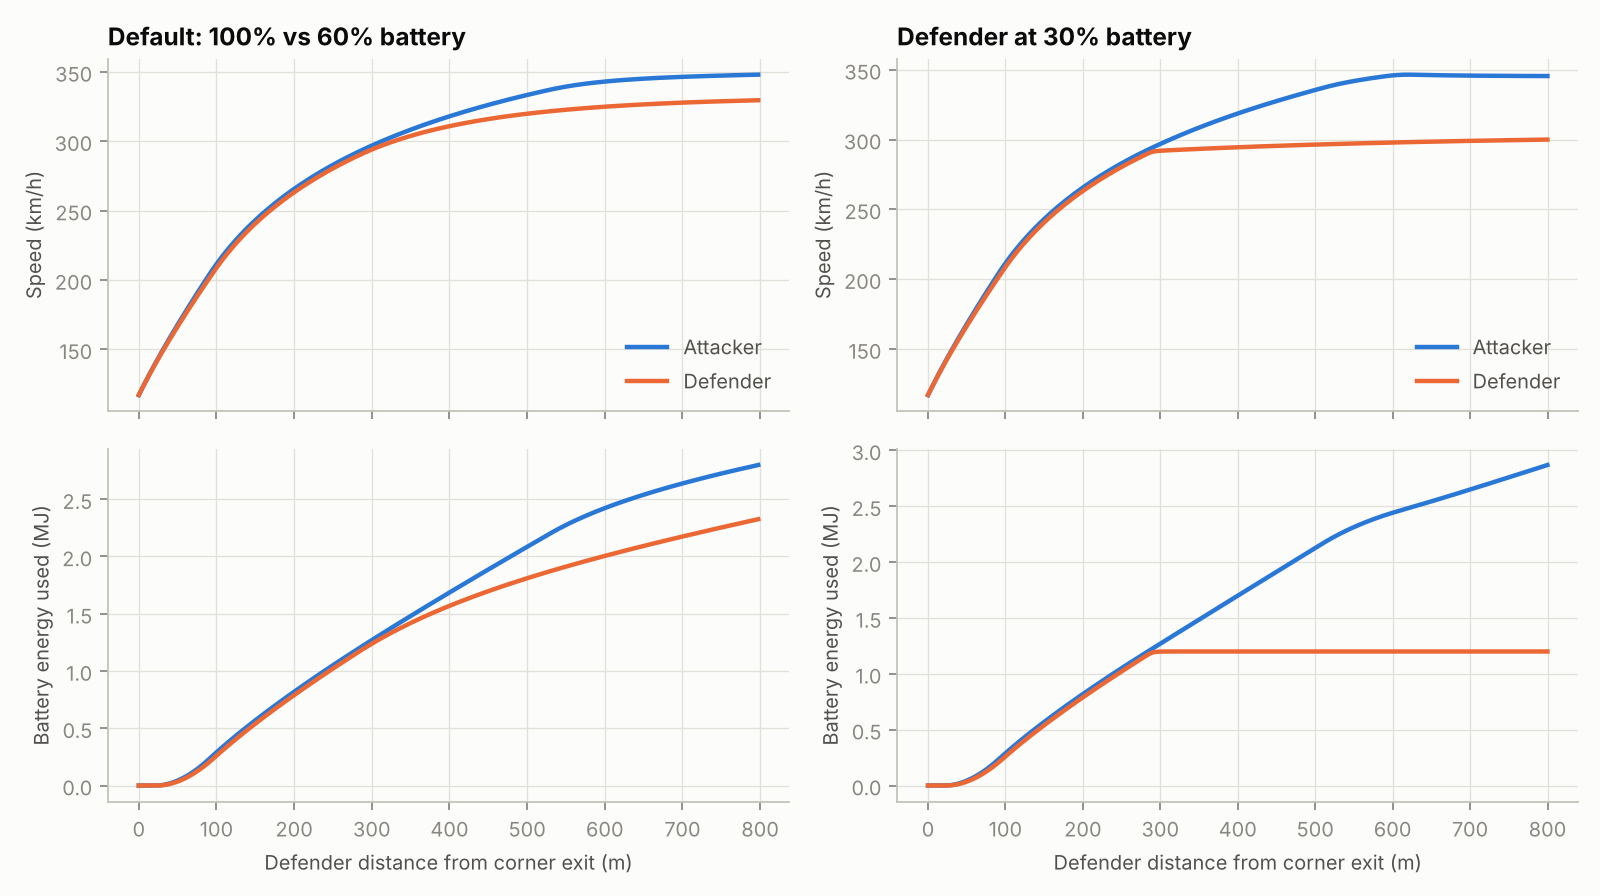

In [5]:
display(Image(FIGURES / "speed_trace.png"))

## 2. Network prediction against the exact probability

In [6]:
network = OvertakePredictor.load()
scenarios = pd.DataFrame([
    DEFAULTS,
    {**DEFAULTS, "attacker_boost": False},
    {**DEFAULTS, "gap_s": 0.5},
    {**DEFAULTS, "defender_battery": 30.0},
    {**DEFAULTS, "circuit": "monaco"},
    {**DEFAULTS, "track_condition": "wet", "attacker_tyre": "intermediate", "defender_tyre": "intermediate",
     "track_temp_c": 20.0},
], index=["default", "no Boost", "0.5 s gap", "defender 30% battery", "Monaco", "wet, inters"])
pd.DataFrame({"network": network.predict(scenarios), "exact (simulator)": simulator.probability(scenarios)},
             index=scenarios.index).round(3)

,network,exact (simulator)
default,0.440,0.474
no Boost,0.007,0.003
0.5 s gap,0.777,0.782
defender 30% battery,0.910,0.928
Monaco,0.175,0.189
"wet, inters",0.198,0.303


## 3. Verification of the numerical methods

In [7]:
solver = load("solver")
{title: {"RK4 order": round(r["rk4_order"], 2), "Euler order": round(r["euler_order"], 2)}
 for title, r in solver.items()}

{'Constant power, no drag': {'RK4 order': 4.05, 'Euler order': 0.95},
 'Drag only, no power': {'RK4 order': 4.0, 'Euler order': 1.0}}

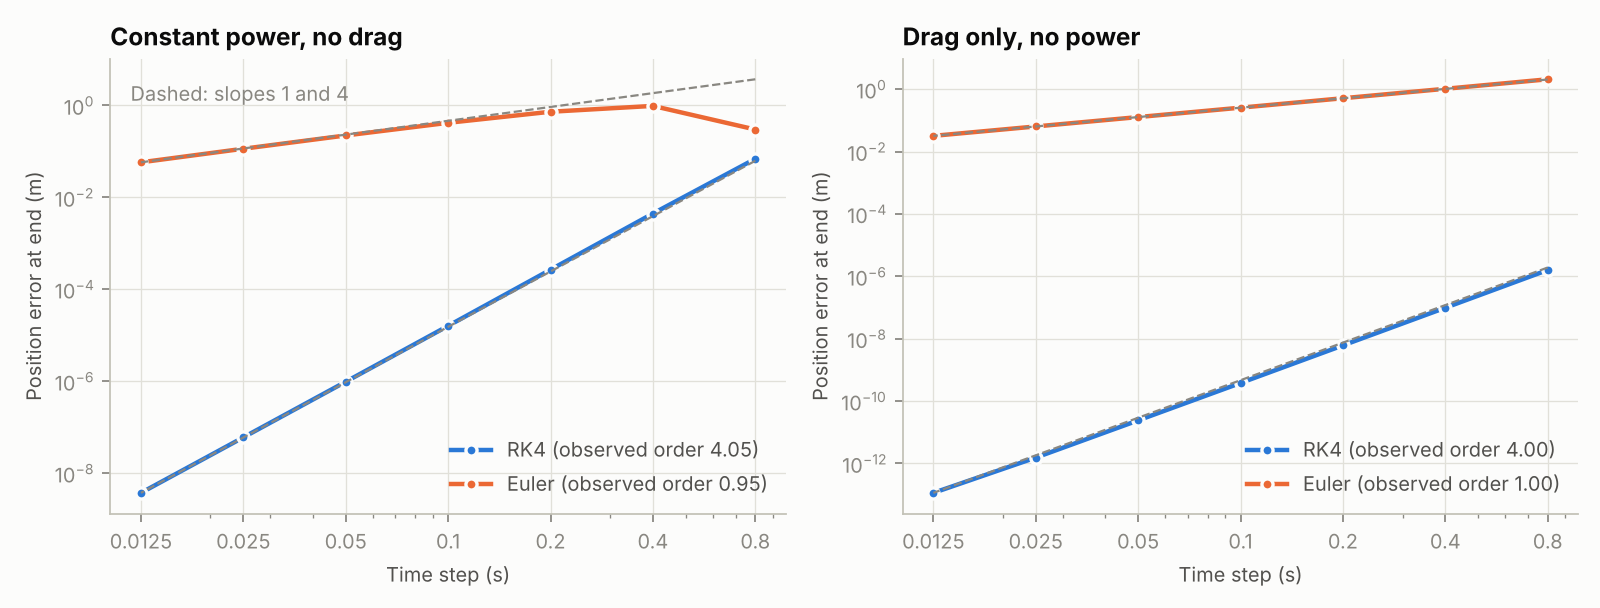

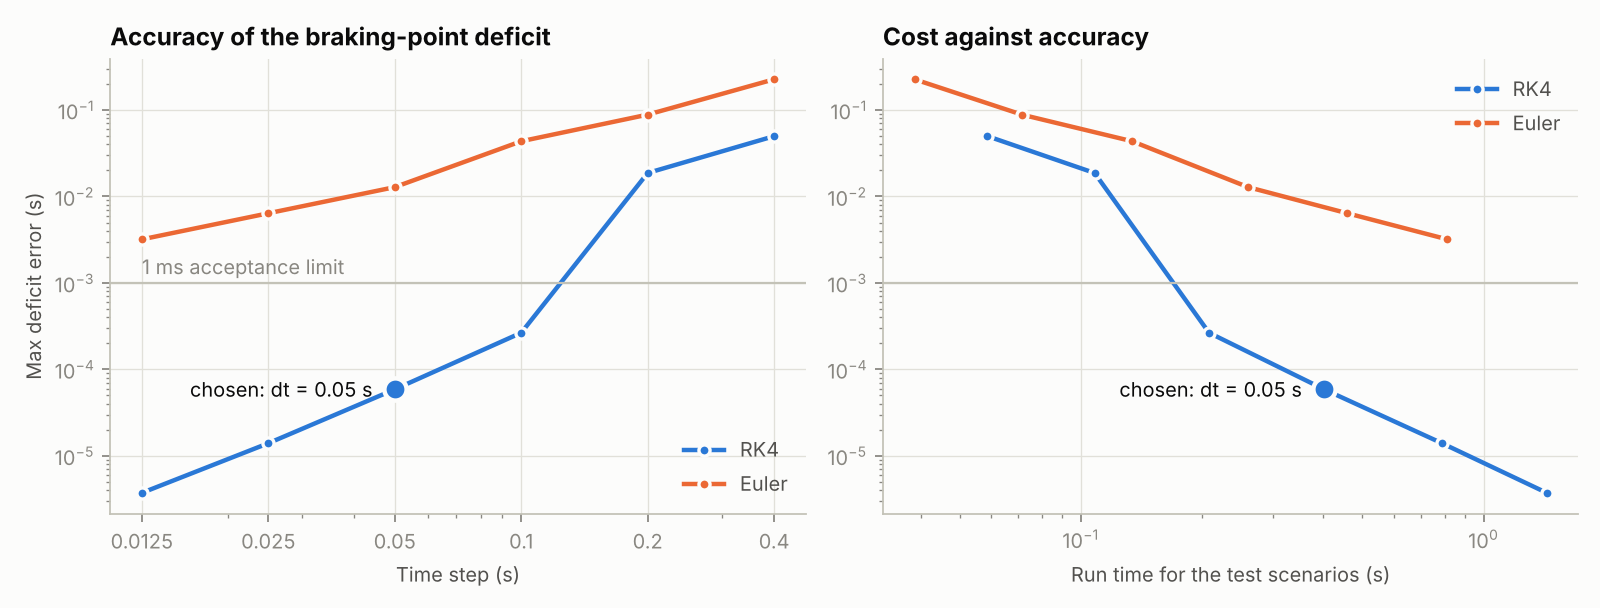

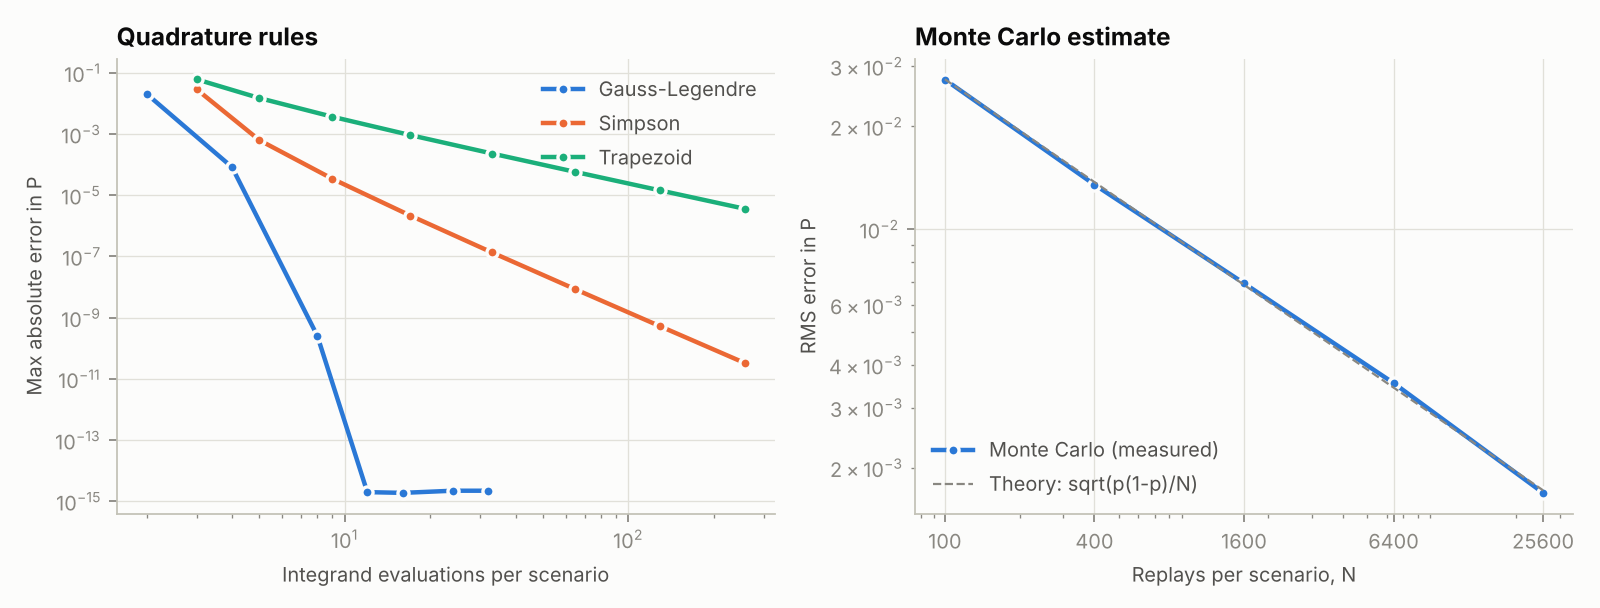

In [8]:
display(Image(FIGURES / "solver_convergence.png"))
display(Image(FIGURES / "timestep_study.png"))
display(Image(FIGURES / "quadrature_study.png"))

## 4. Model selection and comparison with alternatives

In [9]:
selection = load("selection")
print("selected:", selection["selected"], "-", selection["selection_rule"])
pd.DataFrame(selection["architectures"]).set_index("label")[
    ["parameters", "flops_per_prediction", "epochs", "fit_seconds", "val_log_loss", "val_log_loss_se",
     "val_mae_vs_true"]].round(4)

selected: 64-64 - smallest network within one standard error of the lowest validation log loss


,parameters,flops_per_prediction,epochs,fit_seconds,val_log_loss,val_log_loss_se,val_mae_vs_true
label,,,,,,,
32,1309,2369,55,30.7115,0.2671,0.0029,0.0339
64-64,6589,13313,53,46.1680,0.2594,0.0029,0.0218
128-128-64,29373,59649,32,46.8296,0.2591,0.0029,0.0228
256-256-128,107709,217601,25,62.5863,0.2606,0.0030,0.0260


Physics-informed inputs and ensembling: the selected network trained with
five seeds, with and without the energy-cover inputs (validation set; single
networks are the mean over seeds):

In [10]:
ablation = load("ablation")
rows = {}
for name in ("raw inputs only", "with energy-cover inputs"):
    rows[f"{name}: single network"] = {k: v["mean"] for k, v in ablation[name]["single_model"].items()}
    rows[f"{name}: ensemble of 5"] = ablation[name]["ensemble_of_5"]
pd.DataFrame(rows).T.round(4)

,val_log_loss,val_mae_vs_true,default_scenario_error,battery_axis_max_error
raw inputs only: single network,0.2595,0.0224,-0.0346,0.0776
raw inputs only: ensemble of 5,0.2585,0.0202,-0.0346,0.0736
with energy-cover inputs: single network,0.2589,0.0218,0.0032,0.1259
with energy-cover inputs: ensemble of 5,0.2580,0.0197,0.0032,0.1255


In [11]:
comparison = load("comparison")
pd.DataFrame(comparison["models"]).T[
    ["mae_vs_true", "log_loss", "brier", "roc_auc", "calibration_error", "fit_seconds",
     "predict_us_per_scenario", "model_bytes"]].astype(float).round(4)

,mae_vs_true,log_loss,brier,roc_auc,calibration_error,fit_seconds,predict_us_per_scenario,model_bytes
Neural network,0.0203,0.2565,0.0808,0.9477,0.0052,207.9391,4.0624,131780.0
Logistic regression,0.1565,0.4114,0.1318,0.8527,0.0042,2.6223,3.6215,4194.0
Gradient boosting,0.0378,0.2667,0.0832,0.9443,0.0141,4.3379,8.6400,1138666.0
Direct simulation,0.0000,NaN,NaN,NaN,NaN,NaN,93.9184,NaN


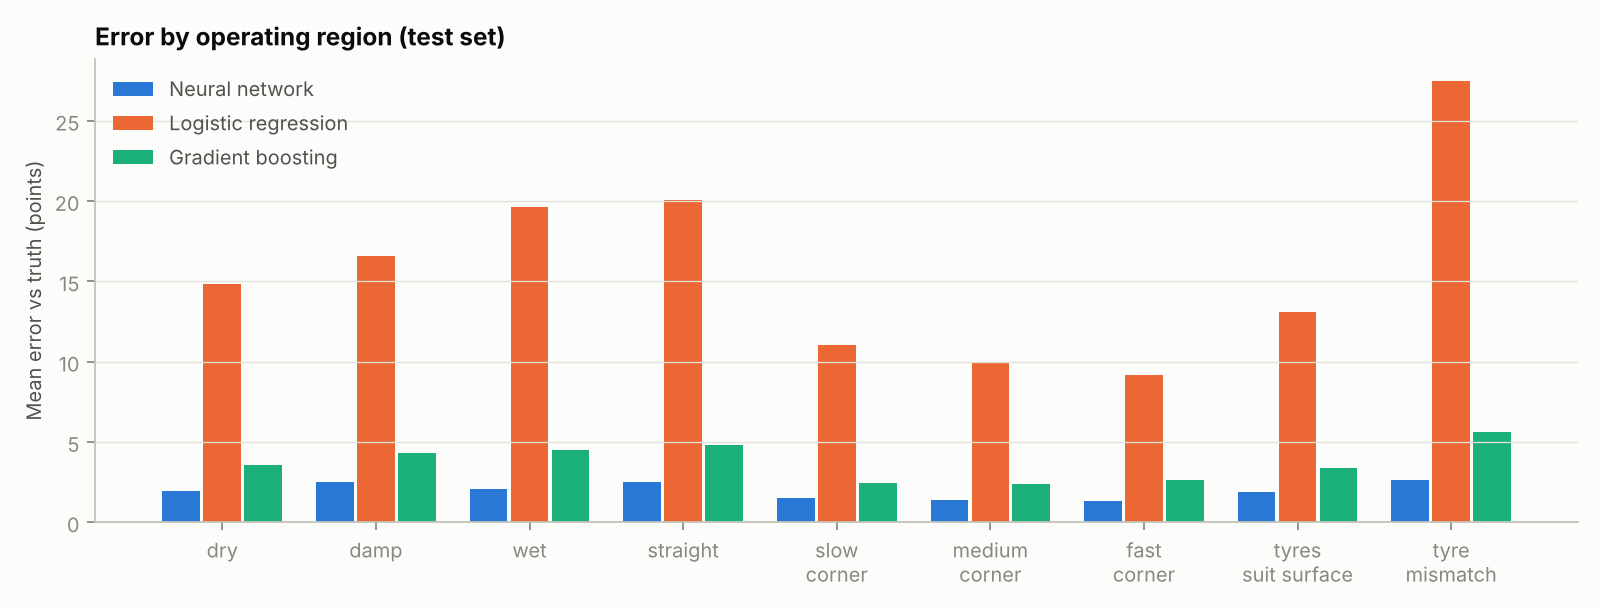

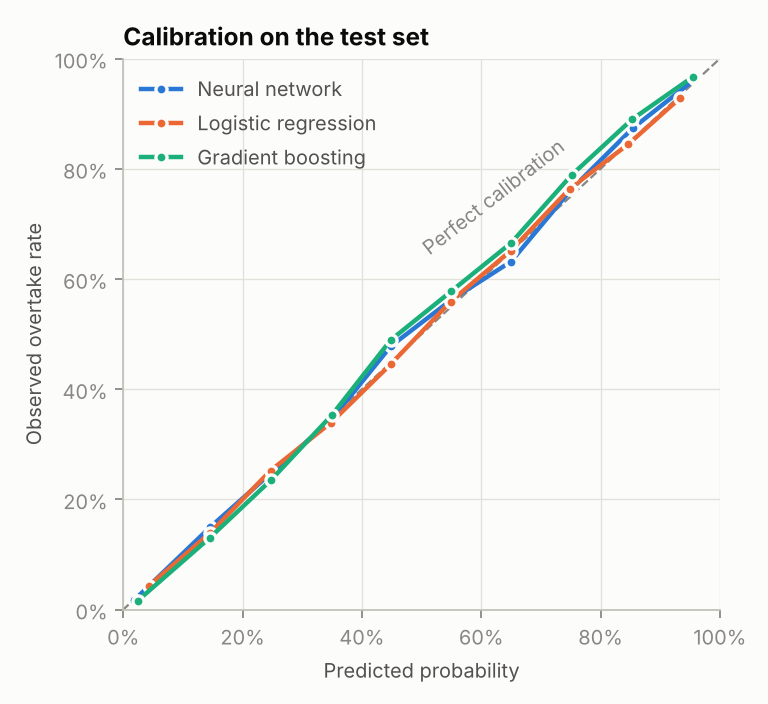

In [12]:
display(Image(FIGURES / "method_comparison.png"))
display(Image(FIGURES / "calibration.png"))

## 5. Sensitivity

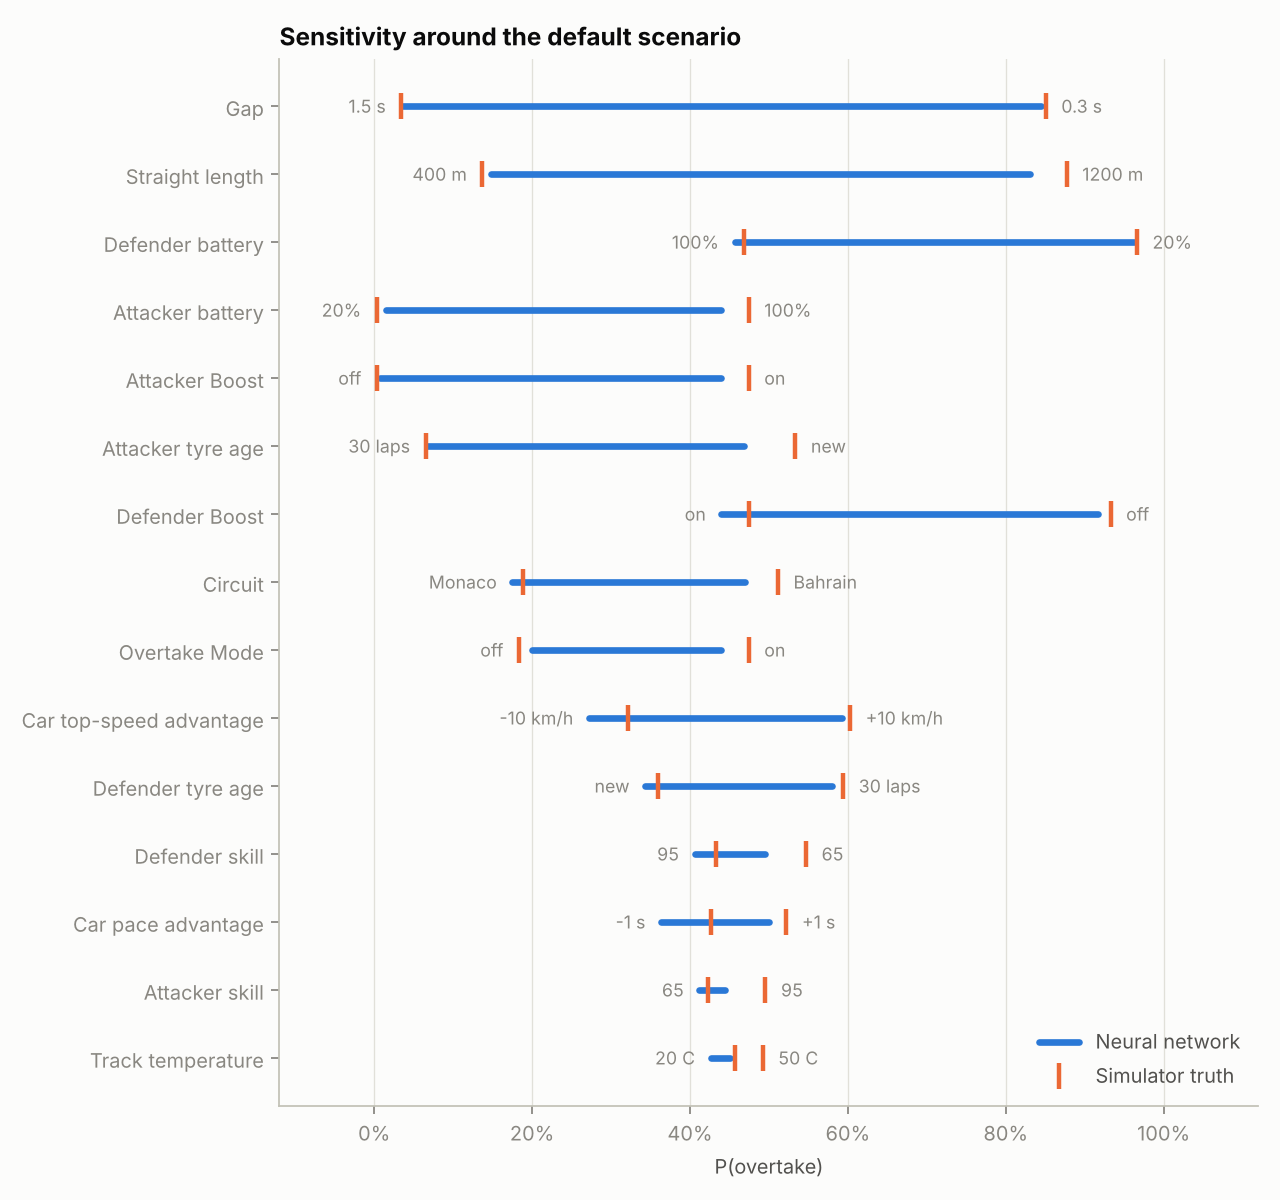

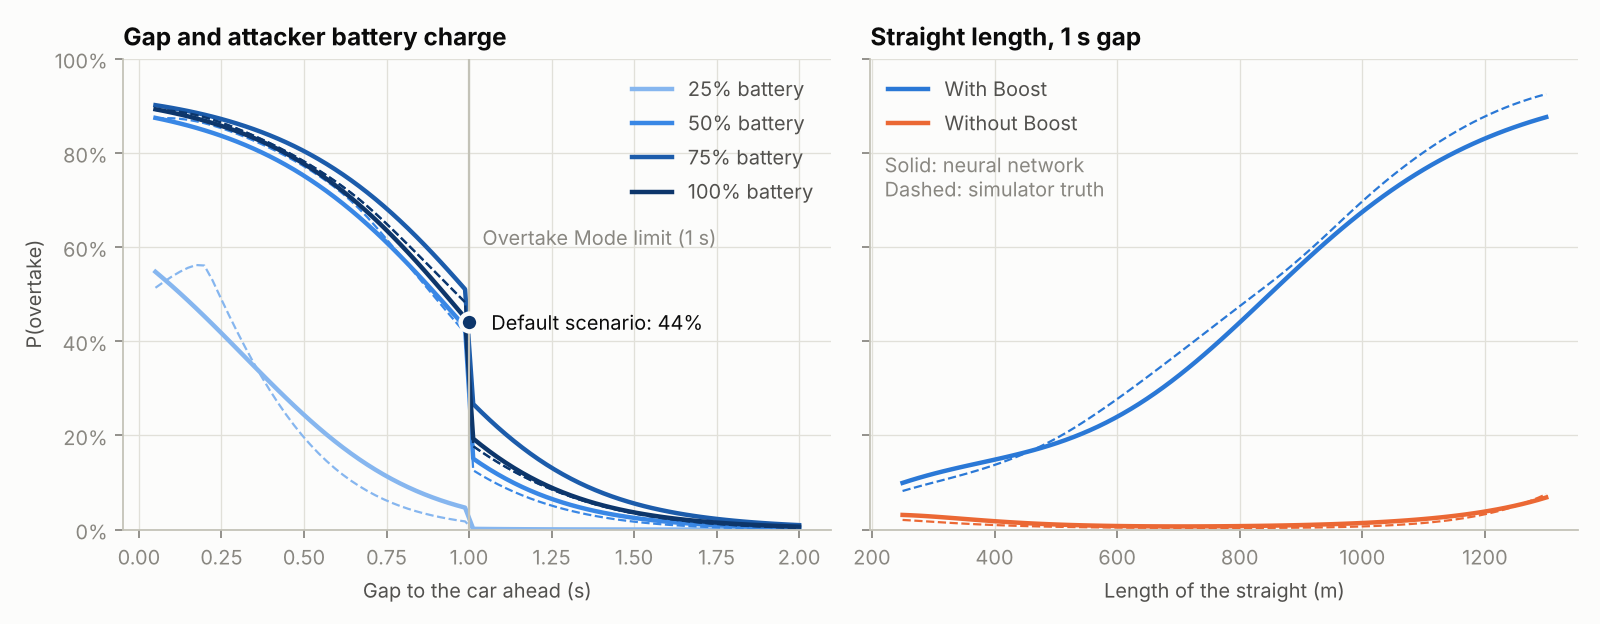

In [13]:
display(Image(FIGURES / "sensitivity.png"))
display(Image(FIGURES / "what_if.png"))